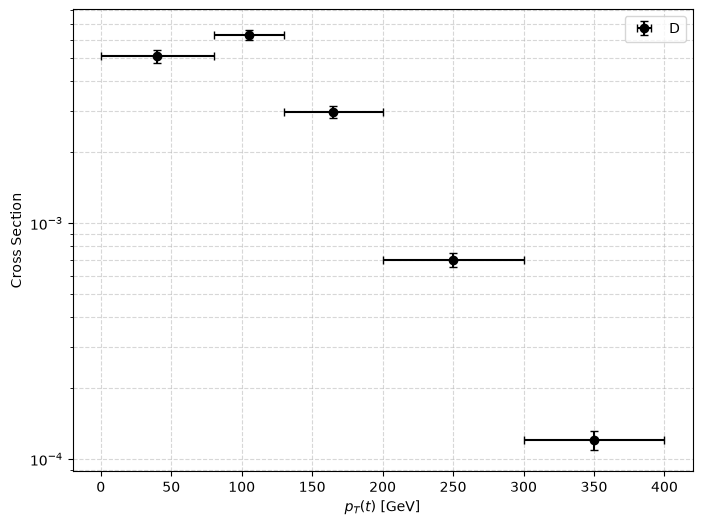

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/cms_table5_dileptons.csv')

df_pt = df[df['variable'] == 'pT_t'].copy()

edges = list(df_pt['bin_min']) + [df_pt['bin_max'].iloc[-1]]

values = df_pt['cross_section'].values

# 5. Будуємо графік
plt.figure(figsize=(8, 6))

# plt.stairs малює гістограму за готовими межами
#plt.stairs(values, edges, label='Переріз pT_l')
# Якщо хочеш лише контур (сходинки) без заливки:
# plt.stairs(values, edges, fill=False, linewidth=2, color='blue')

# 6. Додатково: додаємо похибки (error bars)
# Обчислюємо центри бінів для розташування точок з похибками
x = (df_pt['bin_min'] + df_pt['bin_max']) / 2
# Обчислюємо абсолютну похибку з відсоткової (наприклад, total_err_pct)
y_errors = values * (df_pt['total_err_pct'] / 100.0)
x_errors = (df_pt["bin_max"] - df_pt["bin_min"]) / 2

plt.errorbar(x, values, yerr=y_errors, xerr=x_errors, fmt='o', color='black', capsize=3)

plt.xlabel('$p_{T}(t)$ [GeV]')
plt.ylabel('Cross Section')
plt.yscale('log')
plt.legend("Data")
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.show()